# Criando DataFrames com base nos Datasets

In [37]:
import pandas as pd

# carregando DF de clientes (customers)

In [38]:
df_customers = pd.read_csv('./datasets/churn_customers.csv')

In [39]:
### Mostrando as 5 primeiras linhas da tabela
df_customers.head()

,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [40]:
### Adquirindo informações sobre quantidade de dados, tipos de dados e outras informações da tabela.
df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null   int64
 3   Partner        7043 non-null   str  
 4   Dependents     7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 275.2 KB


# Puxando as demais tabelas

In [41]:
### Importando os arquivos CSV's de "Services" e "Contracts"

df_services = pd.read_csv('./datasets/churn_services.csv')
df_contracts = pd.read_csv('./datasets/churn_contracts.csv')

In [42]:
### Analisando as colunas de services de forma tabular
df_services.head()

,customerID,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,No,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,Yes,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,Yes,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,No,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Yes,No,Fiber optic,No,No,No,No,No,No


In [43]:
### Analisando as informações contidas na tabela services
df_services.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customerID        7043 non-null   str  
 1   PhoneService      7043 non-null   str  
 2   MultipleLines     7043 non-null   str  
 3   InternetService   7043 non-null   str  
 4   OnlineSecurity    7043 non-null   str  
 5   OnlineBackup      7043 non-null   str  
 6   DeviceProtection  7043 non-null   str  
 7   TechSupport       7043 non-null   str  
 8   StreamingTV       7043 non-null   str  
 9   StreamingMovies   7043 non-null   str  
dtypes: str(10)
memory usage: 550.4 KB


In [44]:
### Analisando as colunas de contracts de forma tabular
df_contracts.head()

,customerID,tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,1,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,34,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,2,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,45,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,2,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [45]:
### Analisando as informações de Contracts

df_contracts.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   Contract          7043 non-null   str    
 3   PaperlessBilling  7043 non-null   str    
 4   PaymentMethod     7043 non-null   str    
 5   MonthlyCharges    7043 non-null   float64
 6   TotalCharges      7043 non-null   str    
 7   Churn             7043 non-null   str    
dtypes: float64(1), int64(1), str(6)
memory usage: 440.3 KB


## Transformação de dados

In [46]:
### Identificamos que a coluna TotalCharges está com um tipo diferente do que deveria ser, portanto, precisamos converter o tipo do dado para o correto.
### Devemos, antes de mais nada, garantir que não exista espaços vazios entre os valores. Para isso, usaremos o método 'to_numeric' com o parâmetro errors='coerce'

df_contracts.TotalCharges = pd.to_numeric(df_contracts.TotalCharges, errors='coerce')

In [47]:
### Quando verificamos agora se a conversão funcionou, notamos que o TotalCharges agora é uma coluna do tipo "float64".
### Após a conversão, a coluna TotalCharges, passou a ter 11 valores ausentes.
df_contracts.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   Contract          7043 non-null   str    
 3   PaperlessBilling  7043 non-null   str    
 4   PaymentMethod     7043 non-null   str    
 5   MonthlyCharges    7043 non-null   float64
 6   TotalCharges      7032 non-null   float64
 7   Churn             7043 non-null   str    
dtypes: float64(2), int64(1), str(5)
memory usage: 440.3 KB


## Como renomear colunas em um DF

In [48]:
#Em casos de precisar mudar uma unica coluna específica, podemos usar a expressão abaixo
df_customers.rename(columns={'SeniorCitizen': 'Above65yo'}, inplace=True)

In [49]:
df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   customerID  7043 non-null   str  
 1   gender      7043 non-null   str  
 2   Above65yo   7043 non-null   int64
 3   Partner     7043 non-null   str  
 4   Dependents  7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 275.2 KB


In [50]:
#Como queremos mudar todos os nomes de uma vez, podemos fazer isso da seguinte forma:
df_customers.columns = ['IDCliente', 'Genero', 'Mais65anos', 'TemParceiro', 'TemDependentes']

In [51]:
df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   IDCliente       7043 non-null   str  
 1   Genero          7043 non-null   str  
 2   Mais65anos      7043 non-null   int64
 3   TemParceiro     7043 non-null   str  
 4   TemDependentes  7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 275.2 KB


## Juntando todos os DF em um único (unificação de dataframes)

In [52]:
#Primeiramente, precisamos contar a quantidade de registros por dataframes
len(df_services)

7043

In [53]:
len(df_contracts)

7043

In [54]:
len(df_customers)

7043

In [55]:
 # Verificamos que todos os DFs estão com a mesma quantidade de registros.

Um ponto importante a ser destacado, as 3 tabelas possuem uma coluna em comum "costumer_id". Essa coluna é uma chave que conecta as 3 colunas. É importante lembrar que essa coluna foi renomeada em uma das tabelas para "IDCliente", portanto, devemos deixar em todas as tabelas o mesmo nome.

In [56]:
# Alterando o nome das colunas 'customerID' dos DF services e contracts.
df_services.rename(columns={'customerID': 'IDCliente'}, inplace=True)
df_contracts.rename(columns={'customerID': 'IDCliente'}, inplace=True)

In [57]:
# Unificando os DF Costumers e Services, criando um terceiro DF, onde iremos unir os dois em um.
df_temp = df_customers.merge(df_services, on=['IDCliente'])

In [58]:
#Podemos observar que conseguimos unificar os DFs
df_temp.head()

,IDCliente,Genero,Mais65anos,TemParceiro,TemDependentes,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No


In [59]:
# Unificando os DF df_temp e df_services, criando um df_churn (df definitivo), contendo as informações agora das 3 tabelas.
df_churn = df_temp.merge(df_contracts, on=['IDCliente'])

In [60]:
df_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   IDCliente         7043 non-null   str    
 1   Genero            7043 non-null   str    
 2   Mais65anos        7043 non-null   int64  
 3   TemParceiro       7043 non-null   str    
 4   TemDependentes    7043 non-null   str    
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  tenure            7043 non-null   int64  
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [61]:
df_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   IDCliente         7043 non-null   str    
 1   Genero            7043 non-null   str    
 2   Mais65anos        7043 non-null   int64  
 3   TemParceiro       7043 non-null   str    
 4   TemDependentes    7043 non-null   str    
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  tenure            7043 non-null   int64  
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

# Detectando valores ausentes

In [62]:
# Detectar valores ausentes em todas as colunas do DF

df_churn.isna().sum()

IDCliente            0
Genero               0
Mais65anos           0
TemParceiro          0
TemDependentes       0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
tenure               0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [63]:
# Quantas linhas tem pelo menos uma coluna com valor ausente?

df_churn[df_churn.isna().any(axis=1)]

,IDCliente,Genero,Mais65anos,TemParceiro,TemDependentes,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,No,No phone service,DSL,Yes,No,...,Yes,Yes,No,0,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,0,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,Yes,No,DSL,Yes,Yes,...,No,Yes,Yes,0,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,0,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,No,No phone service,DSL,Yes,Yes,...,Yes,Yes,No,0,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,0,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,0,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,0,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,0,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,Yes,Yes,DSL,No,Yes,...,Yes,Yes,No,0,Two year,No,Mailed check,73.35,NaN,No


In [64]:
# Remover de forma direta e específica a coluna que possui valores ausentes 

df_churn.drop(columns=['TotalCharges'])

,IDCliente,Genero,Mais65anos,TemParceiro,TemDependentes,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,1,Month-to-month,Yes,Electronic check,29.85,No
1,5575-GNVDE,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,34,One year,No,Mailed check,56.95,No
2,3668-QPYBK,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,2,Month-to-month,Yes,Mailed check,53.85,Yes
3,7795-CFOCW,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,45,One year,No,Bank transfer (automatic),42.30,No
4,9237-HQITU,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,2,Month-to-month,Yes,Electronic check,70.70,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,24,One year,Yes,Mailed check,84.80,No
7039,2234-XADUH,Female,0,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,72,One year,Yes,Credit card (automatic),103.20,No
7040,4801-JZAZL,Female,0,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,11,Month-to-month,Yes,Electronic check,29.60,No
7041,8361-LTMKD,Male,1,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,4,Month-to-month,Yes,Mailed check,74.40,Yes


## Imputando valores ausentes

In [65]:
df_churn.fillna(0)

,IDCliente,Genero,Mais65anos,TemParceiro,TemDependentes,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,No,No phone service,DSL,No,Yes,...,No,No,No,1,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,Yes,No,DSL,Yes,No,...,No,No,No,34,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,Yes,No,DSL,Yes,Yes,...,No,No,No,2,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,No,No phone service,DSL,Yes,No,...,Yes,No,No,45,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,Yes,No,Fiber optic,No,No,...,No,No,No,2,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,24,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,72,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,No,No phone service,DSL,Yes,No,...,No,No,No,11,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,Yes,Yes,Fiber optic,No,No,...,No,No,No,4,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


# Análises Univariadas

In [66]:
# Foram definidas 3 hipoteses com base nos dados que foram levantados, são elas:
# - A faixa etaria do cliente em uma forte associação com o churn
# - Um cliente com menos de 6 meses de contrato é mais propenso ao churn
# - Cliente com contrato mensal é mais propenso ao churn

In [67]:
# Contando a quantidade de clientes usando a variável Churn como referência.
df_churn.Churn.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [68]:
# Como é a distribuição de clientes (porcentagem) que abandonaram ou continuaram ativos?
df_churn.Churn.value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

[Text(0, 0, '5174'), Text(0, 0, '1869')]

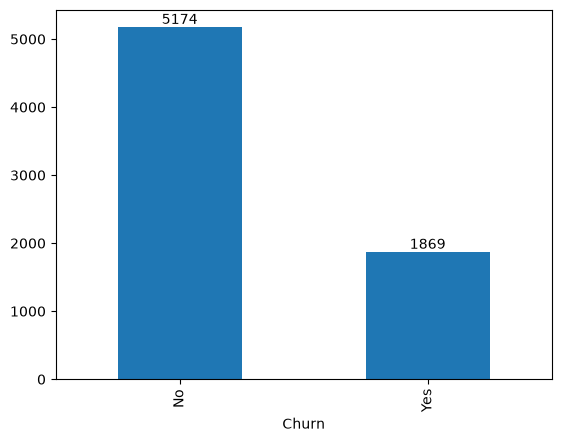

In [69]:
ax = df_churn.Churn.value_counts().plot.bar()

ax.bar_label(ax.containers[0])

In [70]:
# Quais são os tipos de contrato?
df_churn.Contract.unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

[Text(0, 0, '3875'), Text(0, 0, '1695'), Text(0, 0, '1473')]

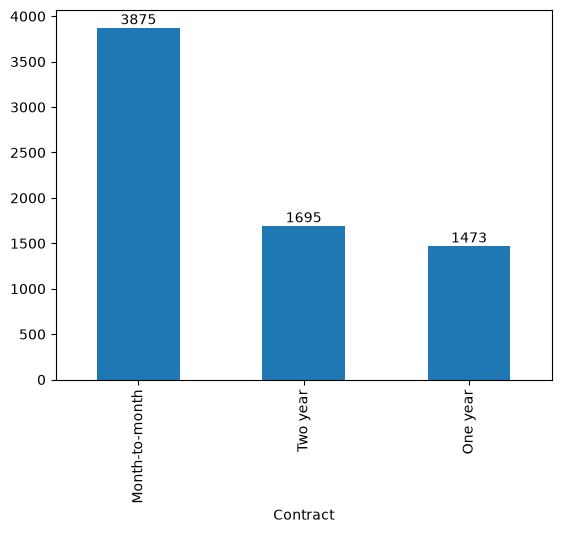

In [71]:
ax = df_churn.Contract.value_counts().plot.bar()

ax.bar_label(ax.containers[0])